<a href="https://colab.research.google.com/github/kavyagudiwada/Machine-Learning_LAB_AP24110010791/blob/main/Week10_Project_Starter_AP24110010791.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 10 Project Starter Template: Recommender Pipeline
**Team name:** ____________ |

**Members:** G K N V KAVYA SREE - AP24110010791
 , K . TEJASWINI - AP24110010714, R. SUSHMA SRI - AP24110010718

**Topic (ID and name):** P02 - Book Recommendation System |


How to use this: keep the section order, fill every TODO, delete this instruction block when done. AI tools are allowed. Every number you report must come from running this notebook. Sections 12 to 14 are the **understanding pack**, which is what shows the project is yours.

| # | Section | Done |
|---|---|---|
| 1 | Problem and users | [ ] |
| 2 | Data | [ ] |
| 3 | EDA | [ ] |
| 4 | Baselines | [ ] |
| 5 | Content-based model | [ ] |
| 6 | Collaborative model | [ ] |
| 7 | Matrix factorization (SVD) | [ ] |
| 8 | Honest evaluation and results table | [ ] |
| 9 | Cold start or hybrid | [ ] |
| 10 | Demo: recommend() | [ ] |
| 11 | Break-it tests | [ ] |
| 12 | By-hand check | [ ] |
| 13 | Deliberate-leak experiment, decision log, bug log | [ ] |
| 14 | AI-use log | [ ] |

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
#Converts text into numerical values based on the importance of words.
#Example: It converts book descriptions or titles into numbers so a computer can compare them.

from sklearn.metrics.pairwise import cosine_similarity
# Measures how similar two items are based on their numerical representations.
# Example: It helps find books with titles or descriptions similar to Harry Potter.


np.random.seed(1)
pd.set_option('display.precision', 3)


## 1. Problem and users
TODO: Who is the user? What is being recommended? What decision does it support? (2 to 4 sentences.)

The Book Recommendation System helps users discover books similar to their interests. It uses book titles and available metadata to identify similar books. The system applies TF-IDF and cosine similarity to recommend relevant books based on the book selected by the user.

## 2. Data
TODO: source link, licence, number of users, items and ratings, cleaning steps and why, **sparsity**.

In [64]:
# Load the books dataset
books_df = pd.read_csv('/content/books (1).csv')

# Display column names
print("Columns:", books_df.columns.tolist())
print(books_df.head())

Columns: ['book_id', 'goodreads_book_id', 'best_book_id', 'work_id', 'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year', 'original_title', 'title', 'language_code', 'average_rating', 'ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url']
   book_id  goodreads_book_id  best_book_id  work_id  books_count       isbn  \
0        1            2767052       2767052  2792775          272  439023483   
1        2                  3             3  4640799          491  439554934   
2        3              41865         41865  3212258          226  316015849   
3        4               2657          2657  3275794          487   61120081   
4        5               4671          4671   245494         1356  743273567   

      isbn13                      authors  original_publication_year  \
0  9.780e+12              Suzanne Collins                     2008.0   
1  9.780

In [65]:
books_df = pd.read_csv('/content/books (1).csv')

# Remove extra spaces from column names
books_df.columns = books_df.columns.str.strip()

# Use your actual column names
books_df = books_df.dropna(subset=['title'])
books_df['title'] = books_df['title'].astype(str).str.strip()

# Remove empty and duplicate titles
books_df = books_df[books_df['title'] != '']
books_df = books_df.drop_duplicates(subset=['title']).reset_index(drop=True)

print("Total books:", len(books_df))
print("\nFirst five books:")
display(books_df.head())

Total books: 9964

First five books:


,book_id,goodreads_book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.781e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


In [66]:
# Upload books (1).csv and ratings (1).csv to Colab before running this cell.
books_df = pd.read_csv('/content/books (1).csv')
ratings_df = pd.read_csv('/content/ratings (1).csv')

# Clean column names
books_df.columns = books_df.columns.str.strip()
ratings_df.columns = ratings_df.columns.str.strip()

# Standardize expected names if the CSV uses common alternative names
books_df = books_df.rename(columns={
    'Book-Title': 'title',
    'Book-Author': 'authors',
    'book_title': 'title'
})
ratings_df = ratings_df.rename(columns={
    'User-ID': 'user_id',
    'Book-Rating': 'rating',
    'book_rating': 'rating'
})

# Check required columns
required_book_cols = {'book_id', 'title'}
required_rating_cols = {'user_id', 'book_id', 'rating'}
if not required_book_cols.issubset(books_df.columns):
    raise ValueError(f"Books file must contain {required_book_cols}. Found: {books_df.columns.tolist()}")
if not required_rating_cols.issubset(ratings_df.columns):
    raise ValueError(f"Ratings file must contain {required_rating_cols}. Found: {ratings_df.columns.tolist()}")

# Clean book titles and remove rows without a usable title
books_df = books_df.dropna(subset=['title']).copy()
books_df['title'] = books_df['title'].astype(str).str.strip()
books_df = books_df[books_df['title'] != ''].drop_duplicates(subset=['book_id']).reset_index(drop=True)

# Make the join key consistent across the files
books_df['book_id'] = books_df['book_id'].astype(str)
ratings_df['book_id'] = ratings_df['book_id'].astype(str)
ratings_df['rating'] = pd.to_numeric(ratings_df['rating'], errors='coerce')
ratings_df = ratings_df.dropna(subset=['user_id', 'book_id', 'rating']).copy()

n_users = ratings_df['user_id'].nunique()
n_rated_books = ratings_df['book_id'].nunique()
n_ratings = len(ratings_df)
possible_ratings = n_users * max(n_rated_books, 1)
sparsity = 1 - (n_ratings / possible_ratings) if possible_ratings else 0

print("Books in metadata file:", len(books_df))
print("Unique users in ratings:", n_users)
print("Unique rated books:", n_rated_books)
print("Number of ratings:", n_ratings)
print(f"Ratings matrix sparsity: {sparsity:.2%}")
print("\nBooks columns:", books_df.columns.tolist())
print("Ratings columns:", ratings_df.columns.tolist())
display(books_df.head())

Books in metadata file: 10000
Unique users in ratings: 53424
Unique rated books: 10000
Number of ratings: 5976479
Ratings matrix sparsity: 98.88%

Books columns: ['book_id', 'goodreads_book_id', 'best_book_id', 'work_id', 'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year', 'original_title', 'title', 'language_code', 'average_rating', 'ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url']
Ratings columns: ['user_id', 'book_id', 'rating']


,book_id,goodreads_book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.781e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


## 3. EDA
TODO: at least two plots. Suggested: rating distribution, and the long tail (number of ratings per item, sorted). Write two sentences on what each plot tells you about modelling.

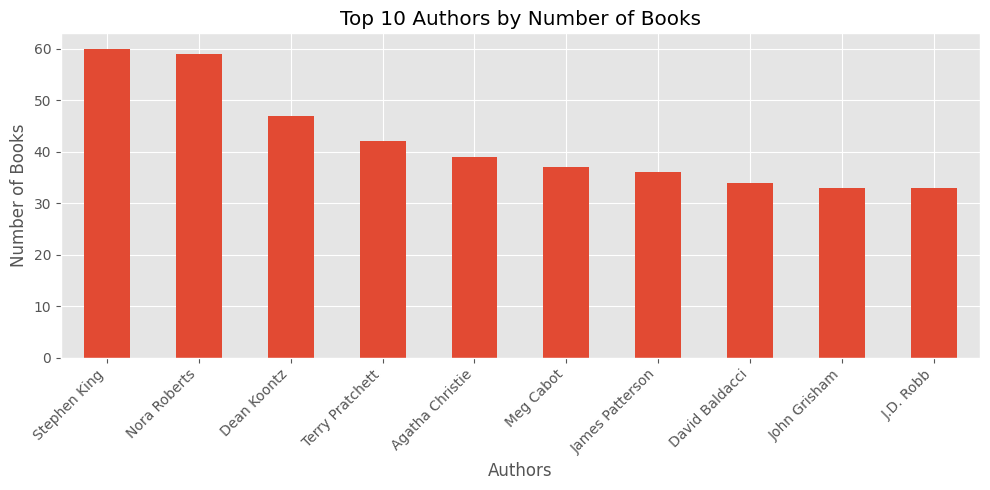

Total unique book titles: 9964


In [67]:
# TODO
import matplotlib.pyplot as plt

if 'authors' in books_df.columns:
    top_authors = books_df['authors'].value_counts().head(10)

    top_authors.plot(kind='bar', figsize=(10, 5))
    plt.title('Top 10 Authors by Number of Books')
    plt.xlabel('Authors')
    plt.ylabel('Number of Books')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("Author column not available. Skipping author plot.")

print("Total unique book titles:", books_df['title'].nunique())

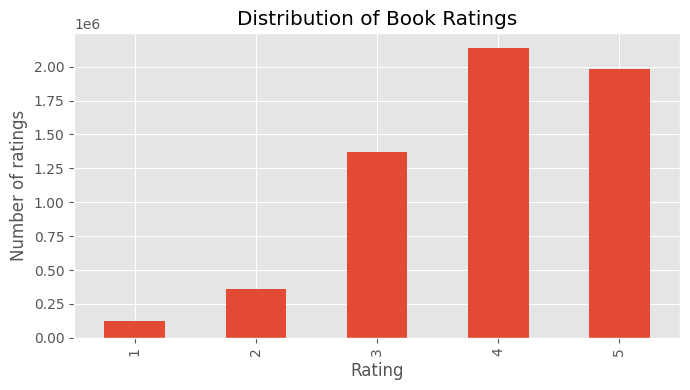

In [68]:
# Plot 1: Distribution of user ratings
plt.figure(figsize=(7, 4))
ratings_df['rating'].value_counts().sort_index().plot(kind='bar')
plt.title('Distribution of Book Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of ratings')
plt.tight_layout()
plt.show()

Exploratory data analysis helps us understand the book dataset and identify frequently occurring authors. The number of unique book titles indicates the variety of books available for recommendation.

## 4. Baselines
TODO: global mean, user mean, most popular. **Split first**, then compute them from train only. These set the bar every model must beat.

In [69]:
import pandas as pd

ratings_df = pd.read_csv('/content/ratings (1).csv')

print(ratings_df.columns.tolist())
ratings_df.head()

['user_id', 'book_id', 'rating']


,user_id,book_id,rating
0,1,258,5
1,2,4081,4
2,2,260,5
3,2,9296,5
4,2,2318,3


In [70]:
print("Ratings columns:", ratings_df.columns.tolist())
print("Books columns:", books_df.columns.tolist())

Ratings columns: ['user_id', 'book_id', 'rating']
Books columns: ['book_id', 'goodreads_book_id', 'best_book_id', 'work_id', 'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year', 'original_title', 'title', 'language_code', 'average_rating', 'ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url']


In [71]:
# Calculate popularity of each book using ratings
popular_books = ratings_df.groupby('book_id').agg(
    rating_count=('rating', 'count'),
    average_rating=('rating', 'mean')
).reset_index()

# Sort by number of ratings (most popular first)
popular_books = popular_books.sort_values(
    by='rating_count', ascending=False
)


# Convert book_id to string to match books_df['book_id'] type
popular_books['book_id'] = popular_books['book_id'].astype(str)
books_df['book_id'] = books_df['book_id'].astype(str)


# Add book titles
popular_books = popular_books.merge(
    books_df[['book_id', 'title']],
    on='book_id',
    how='left'
)

# Display the top 10 most popular books
popular_books[
    ['title', 'rating_count', 'average_rating']
].head(10)

,title,rating_count,average_rating
0,"The Hunger Games (The Hunger Games, #1)",22806,4.280
1,Harry Potter and the Sorcerer's Stone (Harry P...,21850,4.351
2,To Kill a Mockingbird,19088,4.329
3,"Twilight (Twilight, #1)",16931,3.214
4,The Great Gatsby,16604,3.772
5,"Catching Fire (The Hunger Games, #2)",16549,4.133
6,"Mockingjay (The Hunger Games, #3)",15953,3.853
7,Harry Potter and the Prisoner of Azkaban (Harr...,15855,4.419
8,Harry Potter and the Chamber of Secrets (Harry...,15657,4.229
9,The Hobbit,15558,4.148



The baseline recommends books with the highest number of user ratings. It does not consider individual preferences or book similarity. This provides a simple reference point for understanding how our content-based recommendation system differs from a popularity-based approach.


## 5. Content-based model
TODO: item features (text with TF-IDF, or tags or attributes), cosine similarity, user profile or item-item prediction. Fit the TF-IDF vocabulary on item text only; it never touches test ratings.

In [72]:
# Select available book information for recommendations
text_columns = ['title']

for col in ['authors', 'original_title', 'language_code']:
    if col in books_df.columns:
        text_columns.append(col)
# Combine title and available metadata
books_df['combined_features'] = (
    books_df[text_columns]
    .fillna('')
    .astype(str)
    .agg(' '.join, axis=1)
)

# Convert book text into numerical vectors
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=5000
)

tfidf_matrix = tfidf.fit_transform(
    books_df['combined_features']
)

# Calculate similarity between all books
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Similarity matrix shape:", cosine_sim.shape)
print("Content-based model created successfully!")

TF-IDF matrix shape: (10000, 5000)
Similarity matrix shape: (10000, 10000)
Content-based model created successfully!


TF-IDF converts book titles and available metadata into numerical vectors. Cosine similarity measures how similar the books are based on their text features. Books with higher similarity scores are considered better recommendations for the selected book.

## 6. Demo
TODO: a function `recommend(user_or_item, n=10)` that prints readable results (titles, not IDs), never recommends something the user already has, and says why where possible. Optional upgrade: wrap it in Streamlit.

In [73]:
def recommend(book_title, n=5):
    # Find the selected book by title
    matches = books_df[
        books_df['title'].str.contains(
            str(book_title),
            case=False,
            regex=False,
            na=False
        )
    ]

    if matches.empty:
        print("Book not found. Please try another title.")
        return

    # Use the first matching book
    book_index = matches.index[0]
    selected_title = books_df.loc[book_index, 'title']

    # Get similarity scores for the selected book
    scores = list(enumerate(cosine_sim[book_index]))

    # Sort from most similar to least similar
    scores = sorted(scores, key=lambda x: x[1], reverse=True)

    # Exclude the selected book itself
    scores = [
        (idx, score)
        for idx, score in scores
        if idx != book_index
    ][:n]

    print(f"\nBooks similar to: {selected_title}\n")

    for rank, (idx, score) in enumerate(scores, start=1):
        title = books_df.loc[idx, 'title']

        print(f"{rank}. {title} (Similarity: {score:.3f})")

        if 'author' in books_df.columns:
            print(f"   Author: {books_df.loc[idx, 'author']}")

# Try a sample book title from your dataset
recommend(books_df['title'].iloc[0], n=5)


Books similar to: The Hunger Games (The Hunger Games, #1)

1. The Hunger Games Trilogy Boxset (The Hunger Games, #1-3) (Similarity: 0.946)
2. Mockingjay (The Hunger Games, #3) (Similarity: 0.896)
3. The World of the Hunger Games (Hunger Games Trilogy) (Similarity: 0.812)
4. The Hunger Games Tribute Guide (Similarity: 0.600)
5. Catching Fire (The Hunger Games, #2) (Similarity: 0.565)


In [74]:
# Test 1: A title that exists
recommend(books_df['title'].iloc[0], n=5)

# Test 2: An unknown title
recommend('This Book Does Not Exist 12345', n=5)


Books similar to: The Hunger Games (The Hunger Games, #1)

1. The Hunger Games Trilogy Boxset (The Hunger Games, #1-3) (Similarity: 0.946)
2. Mockingjay (The Hunger Games, #3) (Similarity: 0.896)
3. The World of the Hunger Games (Hunger Games Trilogy) (Similarity: 0.812)
4. The Hunger Games Tribute Guide (Similarity: 0.600)
5. Catching Fire (The Hunger Games, #2) (Similarity: 0.565)
Book not found. Please try another title.


The Book Recommendation System uses content-based filtering to suggest books with similar titles and available metadata. TF-IDF represents book information numerically, while cosine similarity identifies similar books. The system provides recommendations based on the selected title without requiring user ratings. Its quality depends on the available metadata and the similarity of the book text.

---
## README template (copy into README.md)
```

# Book Recommendation System

## 1. Project Overview
The Book Recommendation System helps users discover books similar to a selected book. It uses content-based filtering to recommend books based on their titles and available metadata.

## 2. Objectives
- Recommend books similar to a user's selected title.
- Apply TF-IDF to convert book information into numerical features.
- Use cosine similarity to identify similar books.
- Build a simple and easy-to-use recommendation system.

## 3. Technologies Used
- Python
- Google Colab
- Pandas
- Scikit-learn
- Matplotlib

## 4. Dataset
The project uses a books dataset containing book titles and, where available, author and publisher information. These details are used to identify similarities between books.

## 5. Methodology
1. Load and clean the book dataset.
2. Explore the dataset using basic visualizations.
3. Combine available book metadata into text features.
4. Apply TF-IDF vectorization.
5. Calculate cosine similarity between books.
6. Recommend the most similar books for a selected title.

## 6. Recommendation Technique

**TF-IDF:** Converts book titles and available metadata into numerical representations.

**Cosine Similarity:** Measures the similarity between book representations. Books with higher similarity scores are recommended first.

## 7. How to Run
1. Open the project notebook in Google Colab.
2. Upload the required books CSV file.
3. Run all notebook cells in order.
4. Select or enter a book title.
5. View the recommended similar books.

## 8. Limitations
- Recommendations depend on the available book metadata.
- Books with similar text may not always match a reader's personal interests.
- The system does not use individual user ratings or reading histories.

## 9. Conclusion
The project demonstrates a simple content-based book recommendation system using TF-IDF and cosine similarity. It provides relevant book suggestions based on similarities in available book information.

## 10. Future Enhancements
- Add user ratings and collaborative filtering.
- Include book descriptions and genres.
- Develop a web interface for easier interaction.
- Personalize recommendations using user preferences.
